# Drivers EDA (data for Model 1 and Model 2)

Phase 1 data exploration. Read-only: this notebook does not change anything in `data/`.

**Inputs** (built by DVC stages `build_country_panel` and `build_global_budget`):
- `data/processed_drivers/country_panel.csv` - one row per country per year (Model 1).
- `data/processed_drivers/global_carbon_budget.csv` - one row per year, GtC/yr (Model 2).

**Units** (from `data/raw/emissions/owid-co2-codebook.csv` and `src/data/build_country_panel.py`):
- `co2`: million tonnes CO2 (Mt), excludes land-use change.
- `population`: people.
- `gdp`: international-$ in 2011 prices (Maddison Project Database 2023), so `gdp_per_capita` is int-$ (2011) per person.
- `primary_energy_consumption`: terawatt-hours (TWh).
- `energy_per_capita` = primary_energy_consumption / population -> **TWh per person** (multiply by 1e9 for kWh/person). Note: this is *recomputed* by the build script, not OWID's own kWh column.
- `energy_per_gdp` = primary_energy_consumption / gdp -> **TWh per int-$** (multiply by 1e9 for kWh/$).
- `co2_per_capita`: tonnes CO2 per person.
- `carbon_intensity` = co2 / energy (Mt per TWh) - **display only** (derived from the target).

Figures are saved to `reports/eda_drivers/`.

In [21]:
# Find the repo root (folder with dvc.yaml) so the notebook works from the root or from notebooks/
import os
from pathlib import Path

_p = Path.cwd().resolve()
while not (_p / "dvc.yaml").exists():
    if _p.parent == _p:
        raise RuntimeError("Could not find repo root (dvc.yaml)")
    _p = _p.parent
os.chdir(_p)
print("Working directory:", Path.cwd())

Working directory: /Users/sarachhabra/Climate-Change-Awareness-Dashboard


In [22]:
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

FIG_DIR = Path("reports/eda_drivers")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=120, bbox_inches="tight")
    print("saved", path)

SUMMARY = {}   # key numbers collected along the way for the summary table

panel = pd.read_csv("data/processed_drivers/country_panel.csv")
gcb = pd.read_csv("data/processed_drivers/global_carbon_budget.csv")

## 1. Overview
Shape, countries, years, rows per year, countries per year and missing values for both tables.

In [23]:
print("country_panel shape:", panel.shape)
print("countries:", panel["country"].nunique())
print("years:", panel["year"].min(), "-", panel["year"].max(), "(", panel["year"].nunique(), "distinct )")
print("duplicate country-year rows:", int(panel.duplicated(["country", "year"]).sum()))

per_year = panel.groupby("year").agg(rows=("country", "size"), countries=("country", "nunique"))
print("\nrows per year == countries per year for every year:", bool((per_year["rows"] == per_year["countries"]).all()))
print(per_year["countries"].describe().round(1).to_string())
print("\nfirst 3 years:\n", per_year.head(3).to_string())
print("\nlast 3 years:\n", per_year.tail(3).to_string())

yrs_per_country = panel.groupby("country")["year"].nunique()
n_full = int((yrs_per_country == panel["year"].nunique()).sum())
print(f"\ncountries present in all {panel['year'].nunique()} years: {n_full}")
SUMMARY["Panel rows"] = len(panel)
SUMMARY["Panel countries"] = panel["country"].nunique()
SUMMARY["Countries in all 58 years (balanced)"] = n_full
SUMMARY["Countries in 1965 / 2022"] = f"{per_year['countries'].iloc[0]} / {per_year['countries'].iloc[-1]}"

print("\nMissing values per column (country_panel):")
print(panel.isna().sum()[panel.isna().sum() > 0].to_string() if panel.isna().sum().any() else "none")
print("\nzero co2 rows:", int((panel["co2"] == 0).sum()))

country_panel shape: (7757, 22)
countries: 164
years: 1965 - 2022 ( 58 distinct )
duplicate country-year rows: 0

rows per year == countries per year for every year: True
count     58.0
mean     133.7
std       42.1
min       63.0
25%       83.2
50%      161.0
75%      164.0
max      164.0

first 3 years:
       rows  countries
year                 
1965    63         63
1966    63         63
1967    63         63

last 3 years:
       rows  countries
year                 
2020   164        164
2021   164        164
2022   164        164

countries present in all 58 years: 62

Missing values per column (country_panel):
coal_co2                1713
oil_co2                   10
gas_co2                 2547
cement_co2               137
flaring_co2             1759
coal_share_of_co2       1713
oil_share_of_co2          10
gas_share_of_co2        2547
cement_share_of_co2      137
flaring_share_of_co2    1759

zero co2 rows: 0


saved reports/eda_drivers/01_countries_per_year.png


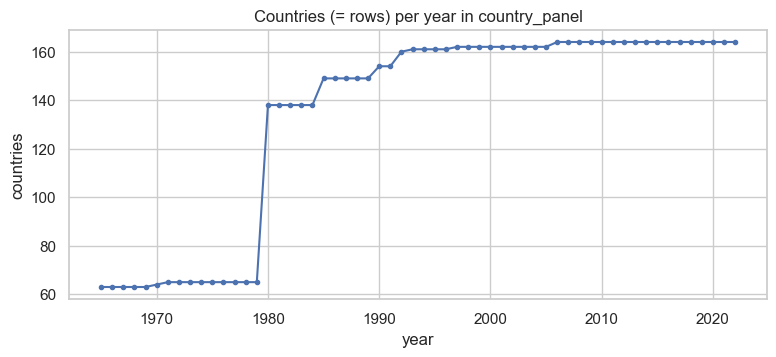

In [24]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(per_year.index, per_year["countries"], marker=".")
ax.set_title("Countries (= rows) per year in country_panel")
ax.set_xlabel("year"); ax.set_ylabel("countries")
save(fig, "01_countries_per_year"); plt.show()

In [25]:
print("global_carbon_budget shape:", gcb.shape, "| years", gcb["year"].min(), "-", gcb["year"].max())
print("\nMissing values per column (global_carbon_budget):")
print(gcb.isna().sum().to_string())
print("\nYears with missing values:")
for c in gcb.columns[gcb.isna().any()]:
    print(f"  {c}: {gcb.loc[gcb[c].isna(), 'year'].tolist()}")

global_carbon_budget shape: (66, 14) | years 1959 - 2024

Missing values per column (global_carbon_budget):
year                        0
fossil_emissions            0
land_use_emissions          0
atmospheric_growth          0
ocean_sink                  0
land_sink                   0
cement_carbonation_sink     0
budget_imbalance            0
total_emissions             0
airborne_fraction           0
atmospheric_growth_ppm      0
co2_ppm_mauna_loa           0
nino34                      0
co2_growth_ppm_mauna_loa    1

Years with missing values:
  co2_growth_ppm_mauna_loa: [1959]


**Finding (Overview):**
- `country_panel` has 7,757 rows x 22 columns, 164 countries, 1965-2022 (58 years), no duplicate country-years. Rows per year = countries per year in every year.
- The panel is **unbalanced**: 63 countries in 1965 and 164 in 2022. Only 62 countries are present in all 58 years. So any raw yearly total will jump when countries enter (see Section 6).
- The model inputs and target (population, gdp, co2, energy and the ratios) have **no missing values** and no zero co2. Missing values exist only in the fuel columns (e.g. gas_co2 2,547, flaring_co2 1,759, coal_co2 1,713) and their display-only shares.
- `global_carbon_budget` has 66 rows (1959-2024). The only missing value is `co2_growth_ppm_mauna_loa` in 1959 (a first difference, so expected).

## 2. Distributions: raw vs log10
Country-level values span several orders of magnitude, so we compare raw and log10 histograms and skewness.
Rows with a value <= 0 cannot be logged and are dropped for the log column only (count printed).

saved reports/eda_drivers/02_distributions_raw_vs_log.png


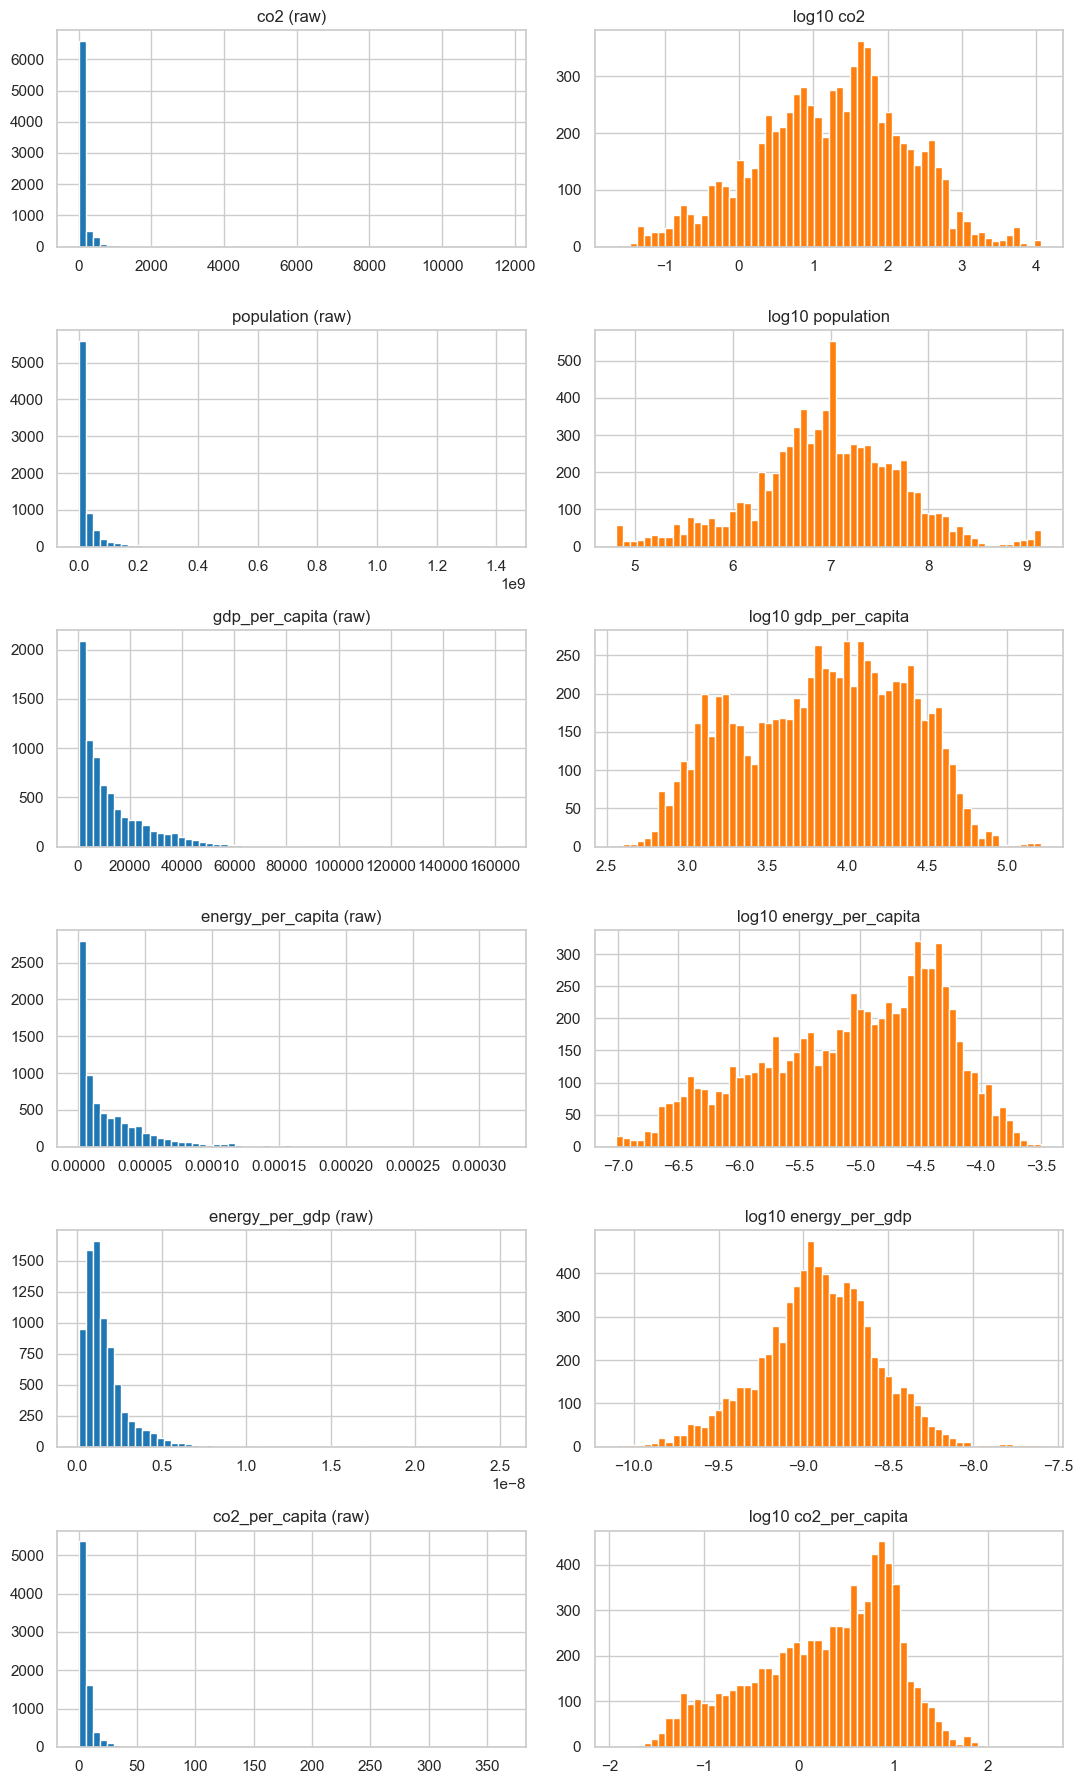

                      n  dropped_for_log(<=0)  skew_raw  skew_log10
column                                                             
co2                7757                     0      9.37       -0.16
population         7757                     0      7.62       -0.17
gdp_per_capita     7757                     0      2.69       -0.15
energy_per_capita  7757                     0      2.66       -0.45
energy_per_gdp     7757                     0      4.83       -0.10
co2_per_capita     7757                     0     11.97       -0.50


In [26]:
DIST_COLS = ["co2", "population", "gdp_per_capita", "energy_per_capita", "energy_per_gdp", "co2_per_capita"]

fig, axes = plt.subplots(len(DIST_COLS), 2, figsize=(11, 3 * len(DIST_COLS)))
rows = []
for i, c in enumerate(DIST_COLS):
    x = panel[c].dropna()
    pos = x[x > 0]
    lx = np.log10(pos)
    axes[i, 0].hist(x, bins=60, color="tab:blue")
    axes[i, 0].set_title(f"{c} (raw)")
    axes[i, 1].hist(lx, bins=60, color="tab:orange")
    axes[i, 1].set_title(f"log10 {c}")
    rows.append({"column": c, "n": len(x), "dropped_for_log(<=0)": len(x) - len(pos),
                 "skew_raw": stats.skew(x), "skew_log10": stats.skew(lx)})
fig.tight_layout()
save(fig, "02_distributions_raw_vs_log"); plt.show()

skew = pd.DataFrame(rows).set_index("column")
print(skew.round(2).to_string())
SUMMARY["Skew co2 raw -> log10"] = f"{skew.loc['co2','skew_raw']:.1f} -> {skew.loc['co2','skew_log10']:.2f}"

**Finding (Distributions):** All six variables are strongly right-skewed on the raw scale (skew 2.66 to 11.97; co2 9.37, co2_per_capita 11.97). After log10 every skew is between -0.50 and -0.10, close to symmetric. No rows had to be dropped for the log (no values <= 0). **A log transform is clearly appropriate** for both inputs and target.

## 3. Relationships in 2022 (log-log)
Each dot is a country in 2022. India, China and the United States are labelled.

countries in 2022: 164
      country      co2  co2_per_capita  gdp_per_capita  energy_kwh_per_person
        China 11711.81            8.22        18921.14               31235.71
        India  2831.13            1.99         7349.57                7057.19
United States  5055.40           14.80        57075.34               77627.72
gdp_per_capita: Pearson r of log10 values in 2022 = 0.907 (n=164)
energy_per_capita: Pearson r of log10 values in 2022 = 0.974 (n=164)
saved reports/eda_drivers/03_scatter_2022_loglog.png


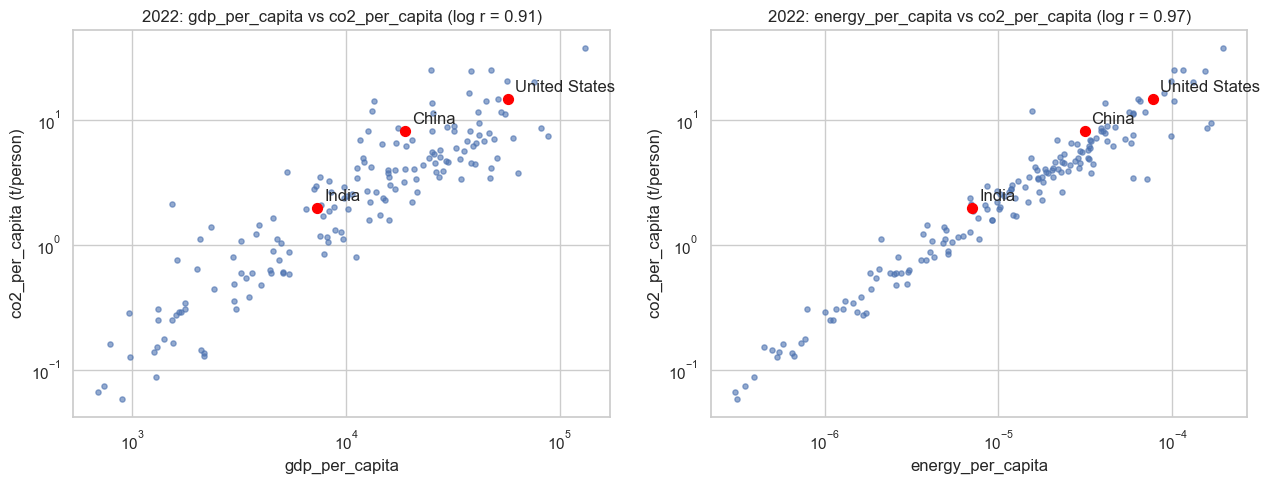

In [27]:
y22 = panel[panel["year"] == 2022].copy()
LABELS = ["India", "China", "United States"]
print("countries in 2022:", len(y22))
print(y22[y22["country"].isin(LABELS)][["country", "co2", "co2_per_capita", "gdp_per_capita"]]
      .assign(energy_kwh_per_person=y22["energy_per_capita"] * 1e9).round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, xc in zip(axes, ["gdp_per_capita", "energy_per_capita"]):
    d = y22[(y22[xc] > 0) & (y22["co2_per_capita"] > 0)]
    ax.scatter(d[xc], d["co2_per_capita"], s=14, alpha=0.6)
    for name in LABELS:
        r = d[d["country"] == name]
        if len(r):
            ax.scatter(r[xc], r["co2_per_capita"], s=50, color="red")
            ax.annotate(name, (r[xc].iloc[0], r["co2_per_capita"].iloc[0]), xytext=(5, 5), textcoords="offset points")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(xc); ax.set_ylabel("co2_per_capita (t/person)")
    r_log = np.corrcoef(np.log10(d[xc]), np.log10(d["co2_per_capita"]))[0, 1]
    ax.set_title(f"2022: {xc} vs co2_per_capita (log r = {r_log:.2f})")
    print(f"{xc}: Pearson r of log10 values in 2022 = {r_log:.3f} (n={len(d)})")
    SUMMARY[f"2022 log r: {xc} vs co2_per_capita"] = round(r_log, 2)
fig.tight_layout()
save(fig, "03_scatter_2022_loglog"); plt.show()

**Finding (Relationships, 2022):** On log-log axes, co2_per_capita tracks energy_per_capita (r = 0.974, n = 164) more tightly than gdp_per_capita (r = 0.907). In 2022 India emits 1.99 t CO2/person (GDP/person 7,350 int-$; energy 7,057 kWh/person), China 8.22 t, the United States 14.80 t. India is low on all three axes and sits within the main cloud, not as an outlier.

## 4. Collinearity of the model inputs (log scale)
Model inputs: `population`, `gdp_per_capita`, `energy_per_capita`, `energy_per_gdp`.
By construction `energy_per_capita = gdp_per_capita * energy_per_gdp`, so in logs one is the exact sum of the other two.

saved reports/eda_drivers/04_input_correlation_heatmap.png


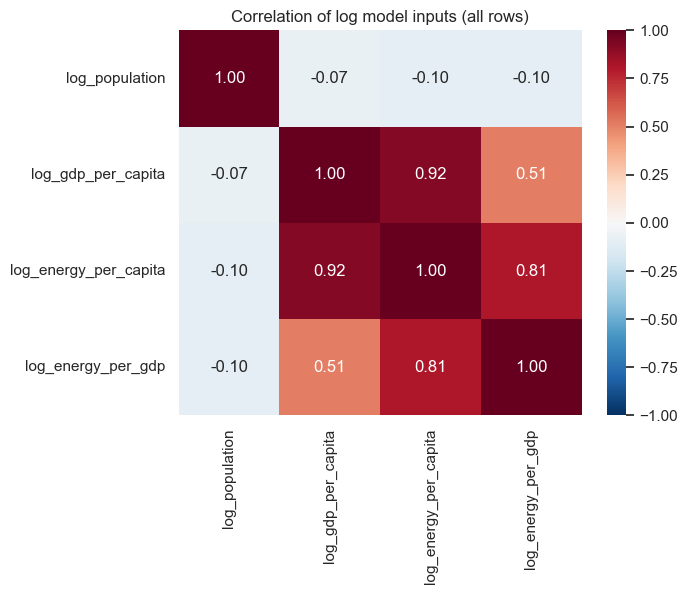

                       log_population  log_gdp_per_capita  log_energy_per_capita  log_energy_per_gdp
log_population                  1.000              -0.075                 -0.098              -0.101
log_gdp_per_capita             -0.075               1.000                  0.920               0.510
log_energy_per_capita          -0.098               0.920                  1.000               0.807
log_energy_per_gdp             -0.101               0.510                  0.807               1.000

Identity check: max |log(epc) - log(gdppc) - log(epg)| = 9.841e-13

VIF (values > 1e6 mean perfect collinearity):
                      all 4 inputs pop + gdppc + epg pop + gdppc + epc pop + epc
log_energy_per_capita          inf                 -              6.52      1.01
log_energy_per_gdp             inf              1.36                 -         -
log_gdp_per_capita             inf              1.35              6.49         -
log_population                1.02              1.01    

In [28]:
INPUTS = ["population", "gdp_per_capita", "energy_per_capita", "energy_per_gdp"]
L = np.log(panel[INPUTS]).replace([np.inf, -np.inf], np.nan).dropna()
L.columns = ["log_" + c for c in INPUTS]

corr = L.corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation of log model inputs (all rows)")
save(fig, "04_input_correlation_heatmap"); plt.show()
print(corr.round(3).to_string())

ident = (L["log_energy_per_capita"] - L["log_gdp_per_capita"] - L["log_energy_per_gdp"]).abs()
print(f"\nIdentity check: max |log(epc) - log(gdppc) - log(epg)| = {ident.max():.3e}")
SUMMARY["Identity max abs error (log)"] = f"{ident.max():.1e}"

def vif_table(cols):
    X = sm.add_constant(L[cols])
    out = {}
    for i, c in enumerate(X.columns):
        if c == "const":
            continue
        try:
            out[c] = variance_inflation_factor(X.values, i)
        except Exception:
            out[c] = np.inf
    return pd.Series(out)

sets = {
    "all 4 inputs": ["log_population", "log_gdp_per_capita", "log_energy_per_capita", "log_energy_per_gdp"],
    "pop + gdppc + epg": ["log_population", "log_gdp_per_capita", "log_energy_per_gdp"],
    "pop + gdppc + epc": ["log_population", "log_gdp_per_capita", "log_energy_per_capita"],
    "pop + epc": ["log_population", "log_energy_per_capita"],
}
vifs = pd.DataFrame({k: vif_table(v) for k, v in sets.items()})
print("\nVIF (values > 1e6 mean perfect collinearity):")
print(vifs.map(lambda v: f"{v:.3g}" if pd.notna(v) else "-").to_string())
SUMMARY["Max VIF, pop+gdppc+epg"] = round(vifs["pop + gdppc + epg"].max(), 2)

**Finding (Collinearity):**
- The identity check gives a max error of 9.8e-13, which is zero up to rounding: **log(energy_per_capita) = log(gdp_per_capita) + log(energy_per_gdp) exactly**. With all four inputs, the VIF is infinite for the three linked ones.
- So the four inputs **cannot all be used together** in a linear model. Use any two of {gdp_per_capita, energy_per_gdp, energy_per_capita} plus population.
- `pop + gdppc + epg` has max VIF 1.36 (cleanest). `pop + gdppc + epc` has VIF about 6.5 because gdp_per_capita and energy_per_capita correlate at r = 0.92 in logs. Population is almost uncorrelated with the others (|r| <= 0.10).

## 5. How much does energy alone decide CO2?
Simple OLS on log values (natural log), all rows with co2 > 0:
- (a) log co2 ~ log energy (total primary energy, TWh)
- (b) log co2 ~ log population + log gdp_per_capita
- (c) log co2 ~ log population + log gdp_per_capita + log energy_per_gdp

Then (b) and (c) out of sample: **time split** (train <= 2010, test 2011-2022) and **country hold-out**
(5 folds, whole countries held out, implemented with numpy). R^2 on the test rows is `1 - SSE/SST` using the test-set mean.

In [29]:
m = panel[(panel["co2"] > 0)].copy()
m["l_co2"] = np.log(m["co2"])
m["l_energy"] = np.log(m["primary_energy_consumption"])
m["l_pop"] = np.log(m["population"])
m["l_gdppc"] = np.log(m["gdp_per_capita"])
m["l_epg"] = np.log(m["energy_per_gdp"])
print("rows used:", len(m), "(dropped co2 == 0:", len(panel) - len(m), ")")

SPECS = {
    "(a) energy": ["l_energy"],
    "(b) pop + gdppc": ["l_pop", "l_gdppc"],
    "(c) pop + gdppc + epg": ["l_pop", "l_gdppc", "l_epg"],
}

def fit(d, cols):
    return sm.OLS(d["l_co2"], sm.add_constant(d[cols])).fit()

def r2_test(model, d, cols):
    pred = model.predict(sm.add_constant(d[cols], has_constant="add"))
    sse = ((d["l_co2"] - pred) ** 2).sum()
    sst = ((d["l_co2"] - d["l_co2"].mean()) ** 2).sum()
    return 1 - sse / sst, np.sqrt(((d["l_co2"] - pred) ** 2).mean())

rows = []
for name, cols in SPECS.items():
    res = fit(m, cols)
    rows.append({"model": name, "in-sample R2": res.rsquared,
                 "in-sample RMSE (log)": np.sqrt(res.mse_resid),
                 "coefs": ", ".join(f"{k}={v:.2f}" for k, v in res.params.items())})
insample = pd.DataFrame(rows).set_index("model")
print(insample.round(3).to_string())

rows used: 7757 (dropped co2 == 0: 0 )
                       in-sample R2  in-sample RMSE (log)                                              coefs
model                                                                                                       
(a) energy                    0.969                 0.407                         const=-1.48, l_energy=0.99
(b) pop + gdppc               0.896                 0.746             const=-24.42, l_pop=0.99, l_gdppc=1.28
(c) pop + gdppc + epg         0.970                 0.398  const=-2.80, l_pop=1.02, l_gdppc=0.96, l_epg=0.94


In [30]:
# Time split
train = m[m["year"] <= 2010]; test = m[m["year"] >= 2011]
print(f"time split: train {len(train)} rows (<=2010), test {len(test)} rows (2011-2022)")

# Country hold-out, 5 folds
rng = np.random.RandomState(42)
countries = m["country"].unique().copy()
rng.shuffle(countries)
folds = np.array_split(countries, 5)

out = []
for name in ["(b) pop + gdppc", "(c) pop + gdppc + epg"]:
    cols = SPECS[name]
    r2_t, rmse_t = r2_test(fit(train, cols), test, cols)
    fold_r2, preds = [], []
    for f in folds:
        tr = m[~m["country"].isin(f)]; te = m[m["country"].isin(f)]
        res = fit(tr, cols)
        fold_r2.append(r2_test(res, te, cols)[0])
        preds.append(pd.Series(res.predict(sm.add_constant(te[cols], has_constant="add")), index=te.index))
    p = pd.concat(preds).reindex(m.index)
    pooled = 1 - ((m["l_co2"] - p) ** 2).sum() / ((m["l_co2"] - m["l_co2"].mean()) ** 2).sum()
    out.append({"model": name, "in-sample R2": insample.loc[name, "in-sample R2"],
                "time-split test R2": r2_t, "time-split test RMSE (log)": rmse_t,
                "country-CV R2 (pooled)": pooled,
                "country-CV R2 per fold min-max": f"{min(fold_r2):.3f}-{max(fold_r2):.3f}"})
oos = pd.DataFrame(out).set_index("model")
print(oos.round(3).to_string())

for name in insample.index:
    SUMMARY[f"In-sample R2 {name}"] = round(insample.loc[name, "in-sample R2"], 3)
for name in oos.index:
    SUMMARY[f"Time-split R2 {name}"] = round(oos.loc[name, "time-split test R2"], 3)
    SUMMARY[f"Country-CV R2 {name}"] = round(oos.loc[name, "country-CV R2 (pooled)"], 3)

time split: train 5789 rows (<=2010), test 1968 rows (2011-2022)
                       in-sample R2  time-split test R2  time-split test RMSE (log)  country-CV R2 (pooled) country-CV R2 per fold min-max
model                                                                                                                                     
(b) pop + gdppc               0.896               0.862                       0.798                   0.894                    0.850-0.914
(c) pop + gdppc + epg         0.970               0.972                       0.360                   0.969                    0.960-0.980


saved reports/eda_drivers/05_r2_comparison.png


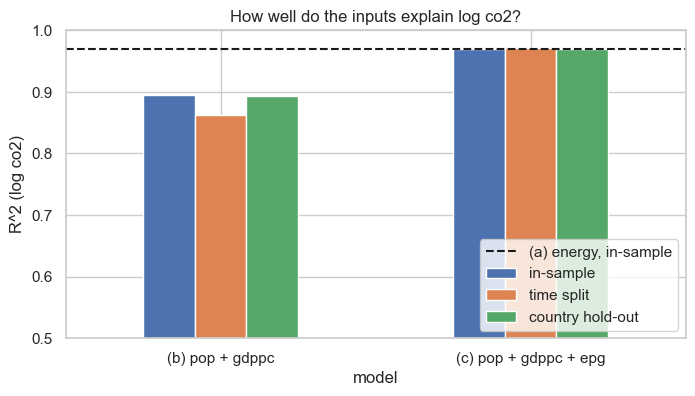

In [31]:
fig, ax = plt.subplots(figsize=(8, 4))
plot = pd.DataFrame({
    "in-sample": [insample.loc[n, "in-sample R2"] for n in oos.index],
    "time split": oos["time-split test R2"].values,
    "country hold-out": oos["country-CV R2 (pooled)"].values,
}, index=oos.index)
plot.plot.bar(ax=ax, rot=0)
ax.axhline(insample.loc["(a) energy", "in-sample R2"], color="k", ls="--", label="(a) energy, in-sample")
ax.set_ylim(0.5, 1.0); ax.set_ylabel("R^2 (log co2)")
ax.set_title("How well do the inputs explain log co2?")
ax.legend(loc="lower right")
save(fig, "05_r2_comparison"); plt.show()

**Finding (How much does energy decide CO2?):**
- Energy alone (a) gives in-sample R^2 = 0.969 with a slope of 0.99, so CO2 is almost proportional to energy use.
- Population + GDP per capita (b) gives 0.896. Adding energy_per_gdp (c) gives 0.970, about the same as energy alone. That is expected: in logs, (c)'s three inputs add up to log total energy.
- Out of sample the picture holds. For (c) the time-split test R^2 is 0.972 and country hold-out is 0.969 (folds 0.960-0.980). For (b) they are 0.862 and 0.894 (folds 0.850-0.914). (b)'s time-split RMSE is 0.798 log units, more than twice (c)'s 0.360.
- **What this means for Model 1:** once energy is an input, the model is mostly an accounting identity (co2 ~ energy x a near-constant carbon intensity). The high R^2 says little about *drivers*. Decide whether Model 1 should (i) predict CO2 from population + economy only (harder, more honest, about 0.86-0.89 out of sample), or (ii) include energy and report that most of the skill comes from energy. Hold out whole countries or late years, not random rows.

## 6. Trends over time
Panel totals of co2, population, gdp and energy, indexed to 1965 = 1. Because the number of countries in the panel
changes over time (Section 1), we also show a **balanced** version using only countries present in all years.

saved reports/eda_drivers/06_trends_indexed.png


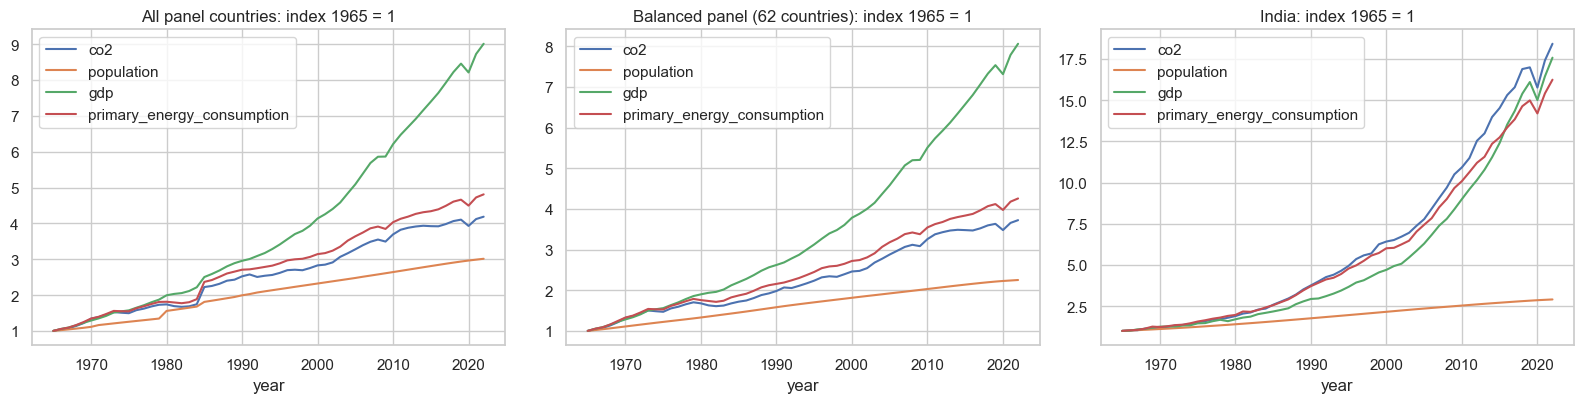

Growth factor 1965 -> 2022:
                            all panel  balanced panel  India
co2                              4.19            3.72  18.42
population                       3.01            2.25   2.91
gdp                              9.01            8.06  17.58
primary_energy_consumption       4.81            4.26  16.24

India years: 1965 - 2022 rows 58


In [32]:
full_countries = yrs_per_country[yrs_per_country == panel["year"].nunique()].index
VARS = ["co2", "population", "gdp", "primary_energy_consumption"]

tot_all = panel.groupby("year")[VARS].sum()
tot_bal = panel[panel["country"].isin(full_countries)].groupby("year")[VARS].sum()
ind = panel[panel["country"] == "India"].set_index("year")[VARS]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=False)
for ax, (title, t) in zip(axes, [("All panel countries", tot_all), (f"Balanced panel ({len(full_countries)} countries)", tot_bal), ("India", ind)]):
    (t / t.iloc[0]).plot(ax=ax)
    ax.set_title(f"{title}: index 1965 = 1"); ax.set_xlabel("year")
fig.tight_layout()
save(fig, "06_trends_indexed"); plt.show()

print("Growth factor 1965 -> 2022:")
gf = pd.DataFrame({"all panel": tot_all.iloc[-1] / tot_all.iloc[0],
                   "balanced panel": tot_bal.iloc[-1] / tot_bal.iloc[0],
                   "India": ind.iloc[-1] / ind.iloc[0]})
print(gf.round(2).to_string())
print("\nIndia years:", ind.index.min(), "-", ind.index.max(), "rows", len(ind))
SUMMARY["India co2 growth 1965->2022 (x)"] = round(gf.loc["co2", "India"], 1)
SUMMARY["Balanced panel co2 growth 1965->2022 (x)"] = round(gf.loc["co2", "balanced panel"], 1)

saved reports/eda_drivers/06_india_vs_panel_pc_and_intensity.png


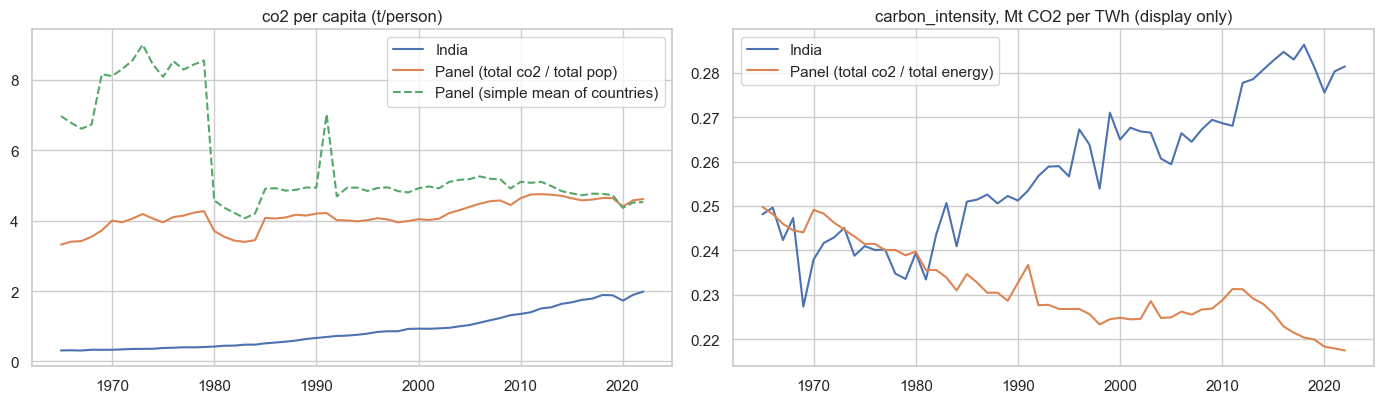

1965: India pc 0.31 t | panel pop-weighted 3.32 t | panel simple mean 6.97 t | India CI 0.248 | panel CI 0.250
1990: India pc 0.67 t | panel pop-weighted 4.20 t | panel simple mean 4.93 t | India CI 0.251 | panel CI 0.233
2022: India pc 1.99 t | panel pop-weighted 4.61 t | panel simple mean 4.53 t | India CI 0.281 | panel CI 0.217


In [33]:
# co2 per capita and carbon intensity: India vs panel
panel_pc = tot_all["co2"] * 1e6 / tot_all["population"]                     # population-weighted
panel_pc_mean = panel.groupby("year")["co2_per_capita"].mean()              # simple mean of countries
india_pc = panel[panel["country"] == "India"].set_index("year")["co2_per_capita"]
panel_ci = tot_all["co2"] / tot_all["primary_energy_consumption"]
india_ci = panel[panel["country"] == "India"].set_index("year")["carbon_intensity"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(india_pc, label="India")
axes[0].plot(panel_pc, label="Panel (total co2 / total pop)")
axes[0].plot(panel_pc_mean, label="Panel (simple mean of countries)", ls="--")
axes[0].set_title("co2 per capita (t/person)"); axes[0].legend()
axes[1].plot(india_ci, label="India")
axes[1].plot(panel_ci, label="Panel (total co2 / total energy)")
axes[1].set_title("carbon_intensity, Mt CO2 per TWh (display only)"); axes[1].legend()
fig.tight_layout()
save(fig, "06_india_vs_panel_pc_and_intensity"); plt.show()

for y in [1965, 1990, 2022]:
    print(f"{y}: India pc {india_pc[y]:.2f} t | panel pop-weighted {panel_pc[y]:.2f} t | "
          f"panel simple mean {panel_pc_mean[y]:.2f} t | India CI {india_ci[y]:.3f} | panel CI {panel_ci[y]:.3f}")

**Finding (Trends):**
- From 1965 to 2022, total CO2 grew 4.19x in the full panel but 3.72x in the balanced panel of 62 countries. Part of the full-panel growth comes from countries entering, not from real growth.
- Over the same period India grew much faster: CO2 18.42x, GDP 17.58x, energy 16.24x, population 2.91x.
- India's co2_per_capita rose from 0.31 t (1965) to 1.99 t (2022). The panel's population-weighted average rose from 3.32 to 4.61 t.
- The simple mean of countries (6.97 t in 1965) is above the population-weighted value, because in 1965 the panel holds fewer, mostly richer countries.
- Carbon intensity (display only): India went from 0.248 to 0.281 Mt/TWh, while the panel fell from 0.250 to 0.217. India's energy mix got more carbon-heavy while the panel's got cleaner.

## 7. India's share
India co2 / panel total co2 per year, and India co2_per_capita relative to the panel average.
The panel is **not the whole world**: it holds only the 164 countries with all four core variables, and country totals
exclude international aviation/shipping. As a check we compare the panel total with GCB global fossil emissions
(converted GtC -> Mt CO2 with x 3.664 x 1000).

saved reports/eda_drivers/07_india_share.png


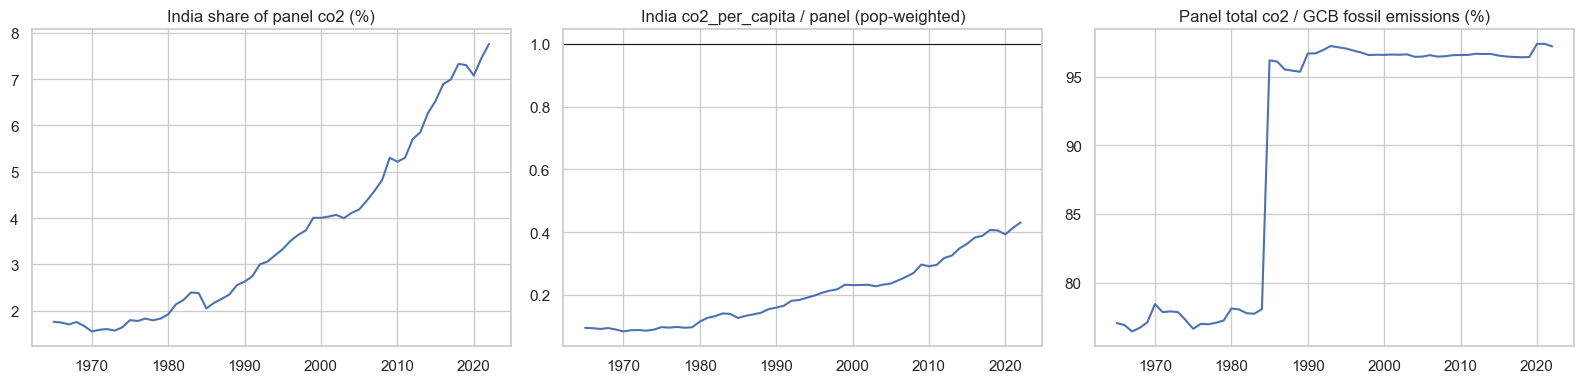

1965: India share 1.8% | India pc / panel pc 0.09 | panel covers 77.1% of GCB fossil
1990: India share 2.6% | India pc / panel pc 0.16 | panel covers 96.7% of GCB fossil
2010: India share 5.2% | India pc / panel pc 0.29 | panel covers 96.6% of GCB fossil
2022: India share 7.8% | India pc / panel pc 0.43 | panel covers 97.2% of GCB fossil

Panel coverage of GCB fossil, min-max over years: 76.4% - 97.4%


In [34]:
share = ind["co2"] / tot_all["co2"]
pc_ratio = india_pc / panel_pc
gcb_mt = gcb.set_index("year")["fossil_emissions"] * 3.664 * 1000
coverage = (tot_all["co2"] / gcb_mt).dropna()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(share * 100); axes[0].set_title("India share of panel co2 (%)")
axes[1].plot(pc_ratio); axes[1].axhline(1, color="k", lw=0.8); axes[1].set_title("India co2_per_capita / panel (pop-weighted)")
axes[2].plot(coverage * 100); axes[2].set_title("Panel total co2 / GCB fossil emissions (%)")
fig.tight_layout()
save(fig, "07_india_share"); plt.show()

for y in [1965, 1990, 2010, 2022]:
    print(f"{y}: India share {share[y]*100:.1f}% | India pc / panel pc {pc_ratio[y]:.2f} | panel covers {coverage[y]*100:.1f}% of GCB fossil")
print(f"\nPanel coverage of GCB fossil, min-max over years: {coverage.min()*100:.1f}% - {coverage.max()*100:.1f}%")
SUMMARY["India share of panel co2 1965 / 2022"] = f"{share[1965]*100:.1f}% / {share[2022]*100:.1f}%"
SUMMARY["India pc / panel pc 2022"] = round(pc_ratio[2022], 2)
SUMMARY["Panel co2 as % of GCB fossil (2022)"] = f"{coverage[2022]*100:.1f}%"

**Finding (India's share):**
- India's share of panel CO2 rose from 1.8% (1965) to 2.6% (1990), 5.2% (2010) and 7.8% (2022). India's co2_per_capita went from 0.09x to 0.43x the panel average.
- **The panel is not the world.** Panel CO2 is 96.6-97.4% of GCB global fossil emissions from 1990 on, but only 77.1% in 1965, because many countries are missing early on.
- So the early-year shares are against a smaller base, and the 1965 share is likely *over*-stated compared with a true world share. This was not verified against a world total for India.

## 8. Global carbon budget (Model 2 data)
All flows in GtC/yr (billion tonnes of carbon). Sinks are positive numbers = carbon removed from the air.

saved reports/eda_drivers/08_budget_components.png


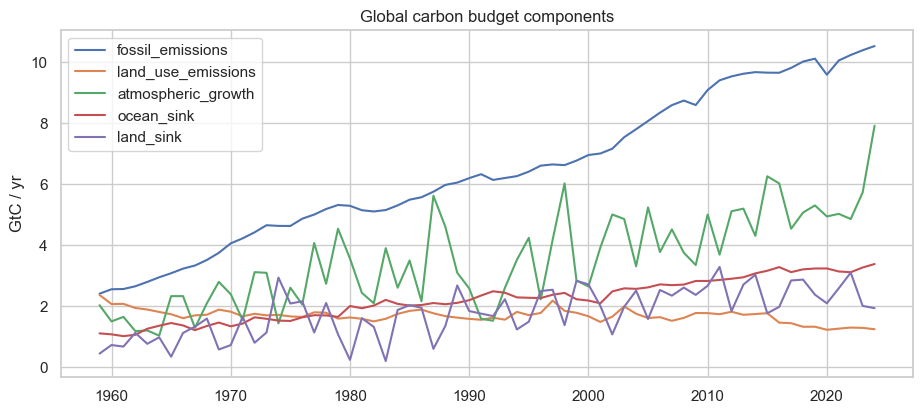

      fossil_emissions  land_use_emissions  atmospheric_growth  ocean_sink  land_sink  budget_imbalance
year                                                                                                   
1959              2.42                2.37                2.04        1.12       0.45              1.17
1990              6.20                1.59                2.59        2.20       1.85              1.10
2024             10.53                1.25                7.92        3.39       1.94             -1.69


In [35]:
g = gcb.set_index("year")
fig, ax = plt.subplots(figsize=(11, 4.5))
for c in ["fossil_emissions", "land_use_emissions", "atmospheric_growth", "ocean_sink", "land_sink"]:
    ax.plot(g.index, g[c], label=c)
ax.set_ylabel("GtC / yr"); ax.set_title("Global carbon budget components"); ax.legend()
save(fig, "08_budget_components"); plt.show()
print(g.loc[[1959, 1990, 2024], ["fossil_emissions", "land_use_emissions", "atmospheric_growth", "ocean_sink", "land_sink", "budget_imbalance"]].round(2).to_string())

saved reports/eda_drivers/08_bookkeeping_cumulative.png


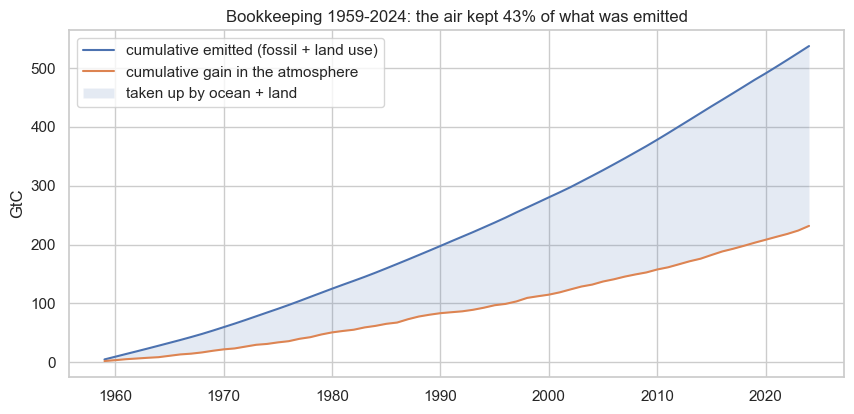

1959-2024: emitted 537 GtC, air gained 232 GtC = 43.1%
years where air gained more than total emissions: 0


In [36]:
cum_emit = g["total_emissions"].cumsum()
cum_air = g["atmospheric_growth"].cumsum()
pct = 100 * cum_air.iloc[-1] / cum_emit.iloc[-1]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(cum_emit, label="cumulative emitted (fossil + land use)")
ax.plot(cum_air, label="cumulative gain in the atmosphere")
ax.fill_between(cum_emit.index, cum_air, cum_emit, alpha=0.15, label="taken up by ocean + land")
ax.set_ylabel("GtC"); ax.legend()
ax.set_title(f"Bookkeeping {g.index.min()}-{g.index.max()}: the air kept {pct:.0f}% of what was emitted")
save(fig, "08_bookkeeping_cumulative"); plt.show()
print(f"{g.index.min()}-{g.index.max()}: emitted {cum_emit.iloc[-1]:.0f} GtC, air gained {cum_air.iloc[-1]:.0f} GtC = {pct:.1f}%")
print("years where air gained more than total emissions:", int((g["atmospheric_growth"] > g["total_emissions"]).sum()))
SUMMARY["Cumulative emitted / air gain (GtC)"] = f"{cum_emit.iloc[-1]:.0f} / {cum_air.iloc[-1]:.0f} ({pct:.1f}%)"

saved reports/eda_drivers/08_airborne_fraction.png


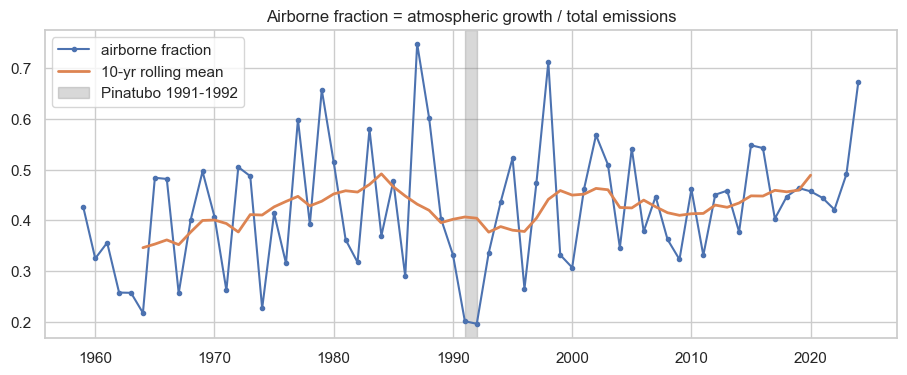

airborne fraction: mean 0.423, sd 0.122, min 0.197 (1992), max 0.747 (1987)
linear trend: +0.0158 per decade (p = 0.04)
1991, 1992 values: [0.202, 0.197]


In [37]:
af = g["airborne_fraction"]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(af, marker=".", label="airborne fraction")
ax.plot(af.rolling(10, center=True).mean(), lw=2, label="10-yr rolling mean")
ax.axvspan(1991, 1992, color="grey", alpha=0.3, label="Pinatubo 1991-1992")
ax.set_title("Airborne fraction = atmospheric growth / total emissions"); ax.legend()
save(fig, "08_airborne_fraction"); plt.show()
slope, _, _, p, _ = stats.linregress(af.index, af.values)
print(f"airborne fraction: mean {af.mean():.3f}, sd {af.std():.3f}, min {af.min():.3f} ({af.idxmin()}), max {af.max():.3f} ({af.idxmax()})")
print(f"linear trend: {slope*10:+.4f} per decade (p = {p:.2f})")
print("1991, 1992 values:", af.loc[[1991, 1992]].round(3).tolist())
SUMMARY["Airborne fraction mean (min-max)"] = f"{af.mean():.2f} ({af.min():.2f}-{af.max():.2f})"

saved reports/eda_drivers/08_airborne_vs_nino.png


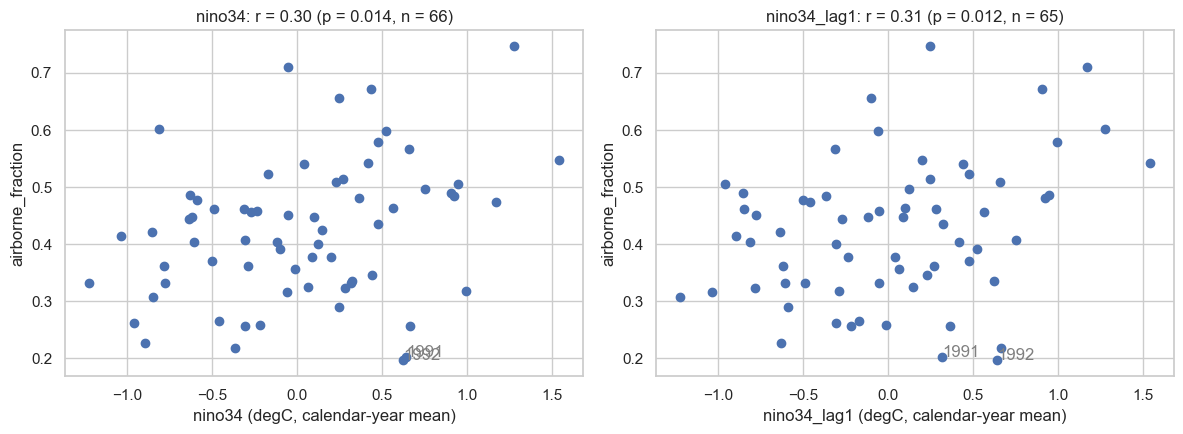

same year: r = 0.302, p = 0.0138, n = 66
Nino lag 1: r = 0.310, p = 0.0119, n = 65


In [38]:
d = g[["airborne_fraction", "nino34"]].copy()
d["nino34_lag1"] = d["nino34"].shift(1)
d0 = d.dropna(subset=["airborne_fraction", "nino34"])
d1 = d.dropna(subset=["airborne_fraction", "nino34_lag1"])
r0, p0 = stats.pearsonr(d0["nino34"], d0["airborne_fraction"])
r1, p1 = stats.pearsonr(d1["nino34_lag1"], d1["airborne_fraction"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (xc, dd, r, p) in zip(axes, [("nino34", d0, r0, p0), ("nino34_lag1", d1, r1, p1)]):
    ax.scatter(dd[xc], dd["airborne_fraction"])
    for yr in [1991, 1992]:
        if yr in dd.index:
            ax.annotate(str(yr), (dd.loc[yr, xc], dd.loc[yr, "airborne_fraction"]), color="grey")
    ax.set_xlabel(f"{xc} (degC, calendar-year mean)"); ax.set_ylabel("airborne_fraction")
    ax.set_title(f"{xc}: r = {r:.2f} (p = {p:.3f}, n = {len(dd)})")
fig.tight_layout()
save(fig, "08_airborne_vs_nino"); plt.show()
print(f"same year: r = {r0:.3f}, p = {p0:.4f}, n = {len(d0)}")
print(f"Nino lag 1: r = {r1:.3f}, p = {p1:.4f}, n = {len(d1)}")
SUMMARY["r(airborne fraction, Nino same yr / lag 1)"] = f"{r0:.2f} / {r1:.2f}"

saved reports/eda_drivers/08_growth_crosscheck.png


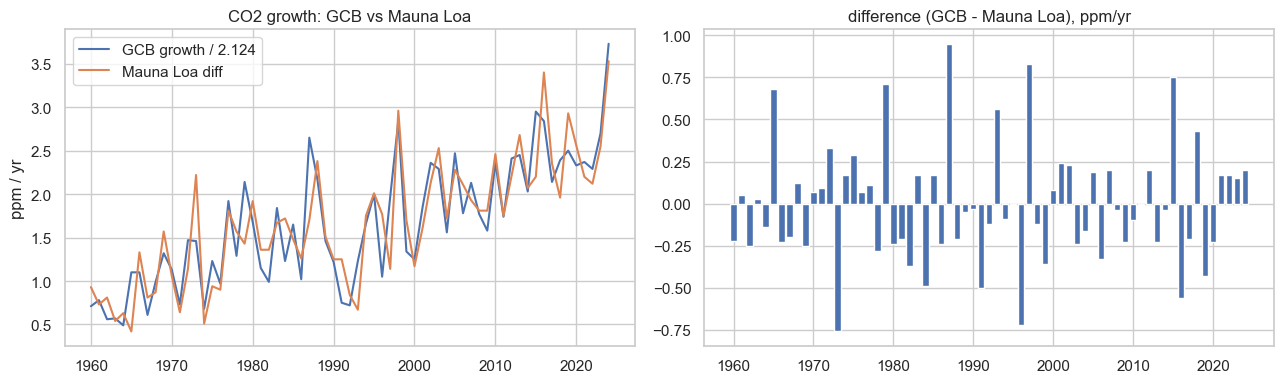

n = 65 years; r = 0.882; mean diff -0.008; mean |diff| 0.266; max |diff| 0.950 ppm/yr (1987)


In [39]:
cc = g[["atmospheric_growth_ppm", "co2_growth_ppm_mauna_loa"]].dropna()
diff = cc["atmospheric_growth_ppm"] - cc["co2_growth_ppm_mauna_loa"]
r_cc = cc.corr().iloc[0, 1]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(cc.index, cc["atmospheric_growth_ppm"], label="GCB growth / 2.124")
axes[0].plot(cc.index, cc["co2_growth_ppm_mauna_loa"], label="Mauna Loa diff")
axes[0].set_ylabel("ppm / yr"); axes[0].legend(); axes[0].set_title("CO2 growth: GCB vs Mauna Loa")
axes[1].bar(diff.index, diff.values); axes[1].set_title("difference (GCB - Mauna Loa), ppm/yr")
fig.tight_layout()
save(fig, "08_growth_crosscheck"); plt.show()
print(f"n = {len(cc)} years; r = {r_cc:.3f}; mean diff {diff.mean():+.3f}; mean |diff| {diff.abs().mean():.3f}; max |diff| {diff.abs().max():.3f} ppm/yr ({diff.abs().idxmax()})")
SUMMARY["GCB vs Mauna Loa growth: r, mean |diff| ppm"] = f"{r_cc:.2f}, {diff.abs().mean():.2f}"

**Finding (Global carbon budget):**
- Fossil emissions rose from 2.42 GtC/yr (1959) to 10.53 (2024). Land-use emissions fell from 2.37 to 1.25.
- Atmospheric growth rose from 2.04 to 7.92. The ocean sink grew from 1.12 to 3.39; the land sink is noisy (0.45 in 1959, 1.94 in 2024).
- **Bookkeeping:** from 1959 to 2024 humans emitted 537 GtC and the air gained 232 GtC (43.1%). In no year did the air gain more than humans emitted (0 of 66). This is consistent with emissions being the source of the rise.
- Airborne fraction has a mean of 0.423 (sd 0.122). It is lowest in 1991 (0.202) and 1992 (0.197), the Pinatubo years, and highest in 1987 (0.747). The linear trend is +0.016 per decade, with p = 0.04 (weak).
- Airborne fraction correlates modestly with Nino 3.4: r = 0.302 same year (p = 0.014) and r = 0.310 with Nino lagged 1 year (p = 0.012). El Nino years leave more carbon in the air.
- Cross-check: GCB growth / 2.124 vs Mauna Loa annual differences gives r = 0.882, mean |diff| 0.266 ppm/yr, largest in 1987 (0.950). They agree on average (mean diff -0.008). Year-to-year differences are expected: GCB uses a global mean, Mauna Loa is one station.

## 9. Summary
Key numbers (collected from the cells above, not typed by hand):

In [40]:
summary_table = pd.Series(SUMMARY, name="value").to_frame()
summary_table.index.name = "metric"
print(summary_table.to_string())

                                                             value
metric                                                            
Panel rows                                                    7757
Panel countries                                                164
Countries in all 58 years (balanced)                            62
Countries in 1965 / 2022                                  63 / 164
Skew co2 raw -> log10                                 9.4 -> -0.16
2022 log r: gdp_per_capita vs co2_per_capita                  0.91
2022 log r: energy_per_capita vs co2_per_capita               0.97
Identity max abs error (log)                               9.8e-13
Max VIF, pop+gdppc+epg                                        1.36
In-sample R2 (a) energy                                      0.969
In-sample R2 (b) pop + gdppc                                 0.896
In-sample R2 (c) pop + gdppc + epg                            0.97
Time-split R2 (b) pop + gdppc                                0

**Decisions for modelling** (each backed by an output above):

1. **Log-transform inputs and target: yes.** Raw skew is 2.7-12.0, after log10 it is between -0.50 and -0.10 (Section 2). The log-log relationships are close to linear (Section 3).
2. **Do not use all four inputs together.** log energy_per_capita = log gdp_per_capita + log energy_per_gdp exactly (max error 9.8e-13; VIF infinite). Use population + any two of the three ratios. `pop + gdppc + epg` has max VIF 1.36 (Section 4).
3. **Never use carbon_intensity or fuel shares as inputs.** They are derived from co2 (build script; Section 6 shows them for display only).
4. **Energy dominates.** Energy alone explains R^2 = 0.969 of log co2. Without energy, population + GDP gives 0.862 (time split) and 0.894 (country hold-out). Decide and document which version Model 1 is (Section 5).
5. **Validate with time or country splits, not random rows.** Out-of-sample R^2 was close to in-sample here, but rows from the same country are not independent (Section 5).
6. **Risk: unbalanced panel.** 63 countries in 1965 vs 164 in 2022; only 62 in every year. Raw totals over time mix real growth with countries joining (4.19x vs 3.72x CO2 growth; Sections 1 and 6).
7. **Risk: panel is not the world.** It covers 77.1% of GCB fossil emissions in 1965 and 97.2% in 2022 (Section 7).
8. **Model 2:** airborne fraction is noisy (sd 0.122), affected by volcanoes (1991-92 lowest) and only weakly linked to Nino (r about 0.30). A year-to-year model of it will have limited skill; the cumulative 43.1% is the robust number (Section 8).